In [1]:
import os
import sys

# Add your module's directory (absolute path or relative path)
module_path = os.path.abspath(os.path.join('../src')) 
if module_path not in sys.path:
    sys.path.insert(0, module_path)


In [2]:
from environments import BanditWalk
from metrics import probability_success, mean_return, play_episode
from display import print_policy, print_transitions, print_state_value_function

from environments import BanditSlipperyWalk
from environments import FrozenLake
from algorithms import policy_improvement, policy_evaluation, policy_iteration
from policy_control import (mc_control, sarsa, q_learning, double_q_learning,
                            sarsa_lambda, q_lambda, dyna_q, trajectory_sampling)

import random
import time
from functools import partial

import numpy as np

In [3]:
slip_walk_seven = BanditSlipperyWalk(n_states=7, start=2, slip_prob=0.5)

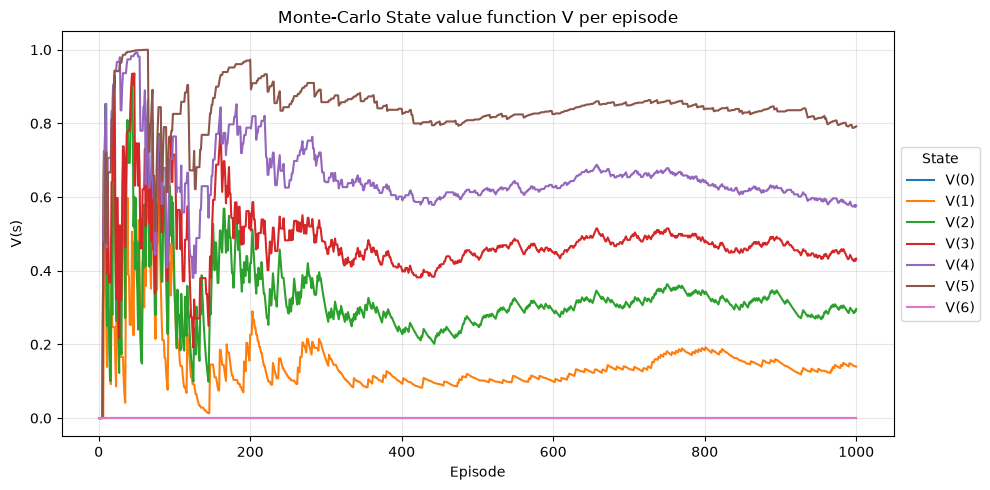

In [4]:
import matplotlib.pyplot as plt


def plot_v_track(V_track: np.ndarray, title: str = 'State-value function V per episode', log_scale: bool = False):
    episodes = np.arange(1, V_track.shape[0] + 1)

    fig, ax = plt.subplots(figsize=(10, 5))
    for s in range(V_track.shape[1]):
        ax.plot(episodes, V_track[:, s], label=f'V({s})')

    if log_scale:
        ax.set_xscale('log')
    ax.set_xlabel('Episode (log scale)' if log_scale else 'Episode')
    ax.set_ylabel('V(s)')
    ax.set_title(title)
    ax.legend(loc='center left', bbox_to_anchor=(1.0, 0.5), title='State')
    ax.grid(True, alpha=0.3)
    fig.tight_layout()
    plt.show()


Q, V_track, pi, Q_track, pi_track = mc_control(slip_walk_seven, n_episodes=1000)
plot_v_track(V_track, title='Monte-Carlo State value function V per episode')

Sarsa, which is TD + epsilon greedy action selection

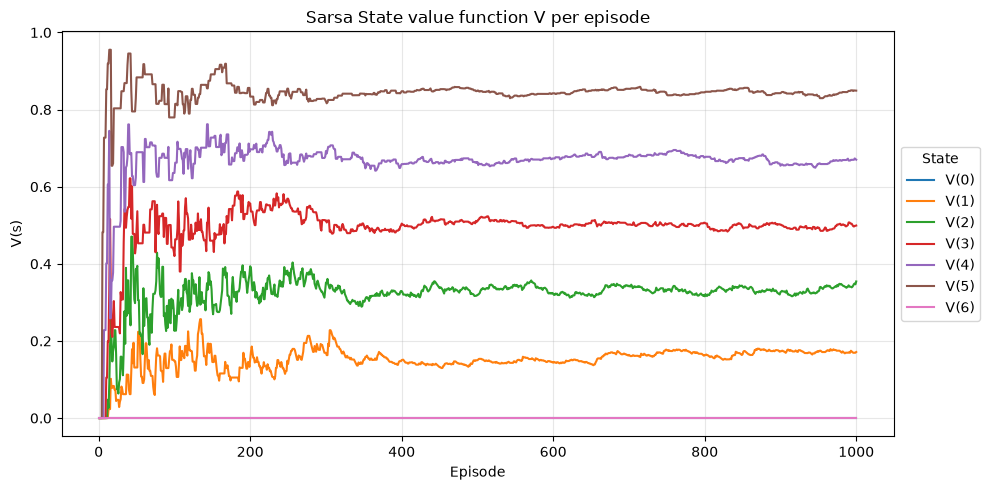

In [5]:
Q, V_track, pi, Q_track, pi_track = sarsa(slip_walk_seven, n_episodes=1000)
plot_v_track(V_track, title='Sarsa State value function V per episode')

Q - Learning

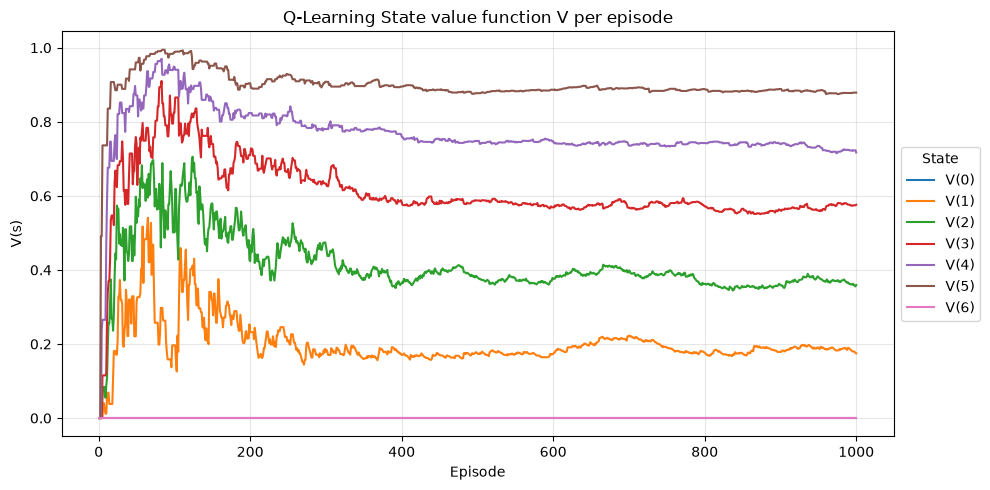

In [6]:
Q, V_track, pi, Q_track, pi_track = q_learning(slip_walk_seven, n_episodes=1000)
plot_v_track(V_track, title='Q-Learning State value function V per episode')

Double Q Learning


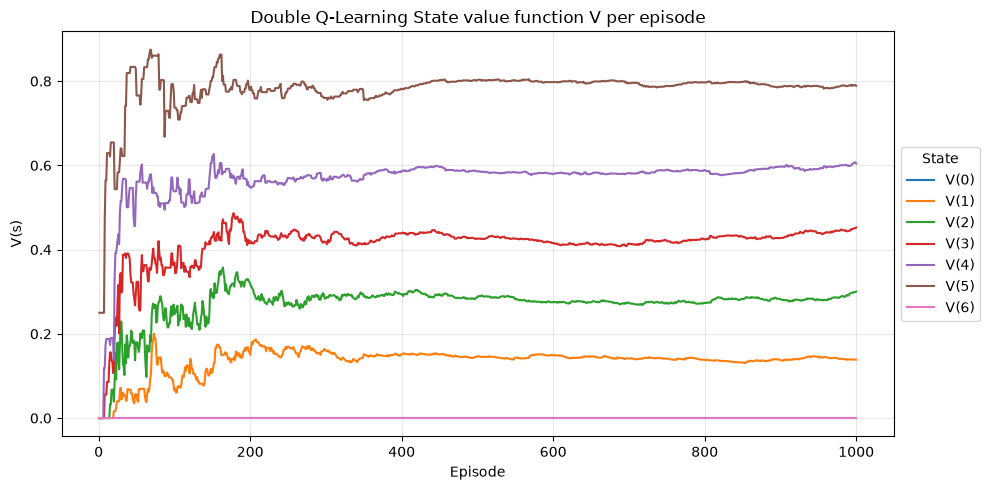

In [7]:
Q, V_track, pi, Q_track, pi_track = double_q_learning(slip_walk_seven, n_episodes=1000)
plot_v_track(V_track, title='Double Q-Learning State value function V per episode')

Sarsa lambda with replacing traces

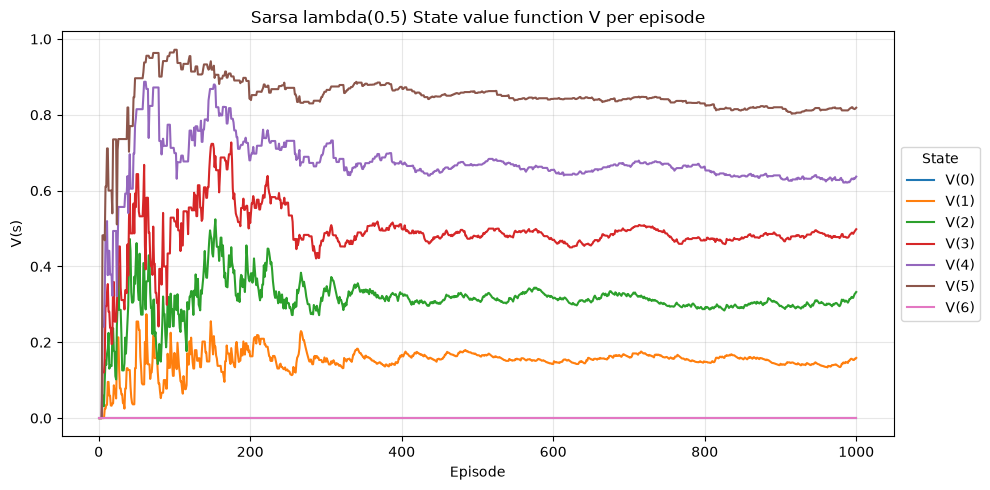

In [8]:
Q, V_track, pi, Q_track, pi_track = sarsa_lambda(slip_walk_seven, n_episodes=1000, lambda_=0.5)
plot_v_track(V_track, title='Sarsa lambda(0.5) State value function V per episode')

Q- learning lambda with eligibility traces

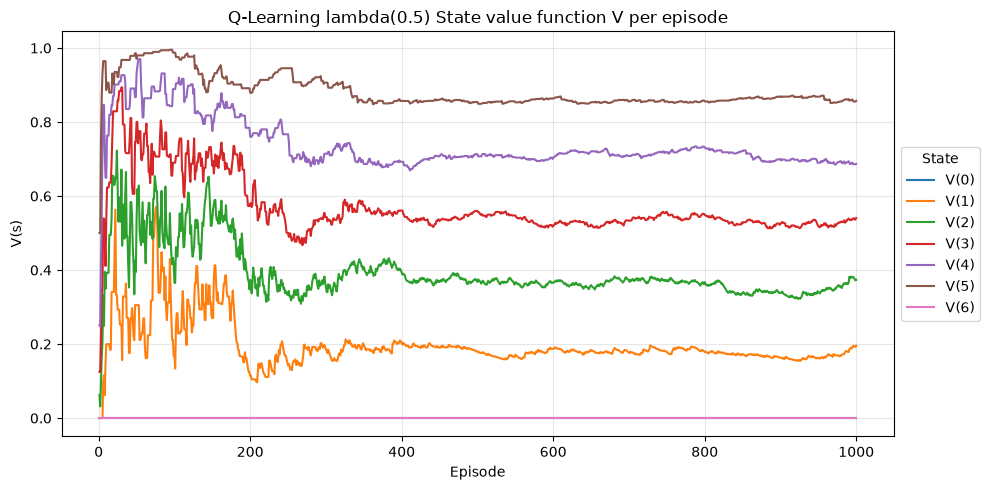

In [9]:
Q, V_track, pi, Q_track, pi_track = q_lambda(slip_walk_seven, n_episodes=1000, lambda_=0.5)
plot_v_track(V_track, title='Q-Learning lambda(0.5) State value function V per episode')

Dyna-Q - Learning the model environment as well

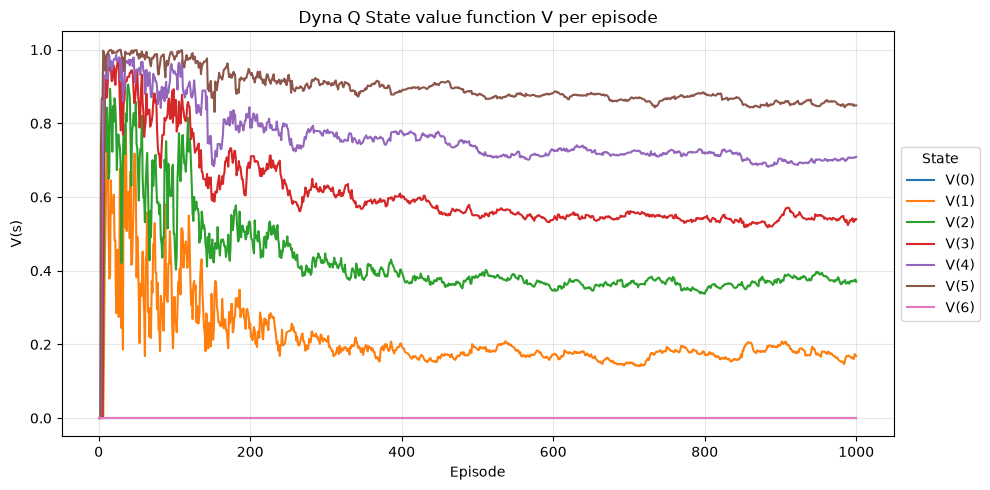

In [10]:

Q, V_track, pi, Q_track, pi_track = dyna_q(slip_walk_seven, n_episodes=1000)
plot_v_track(V_track, title='Dyna Q State value function V per episode')

Trajectory Sampling

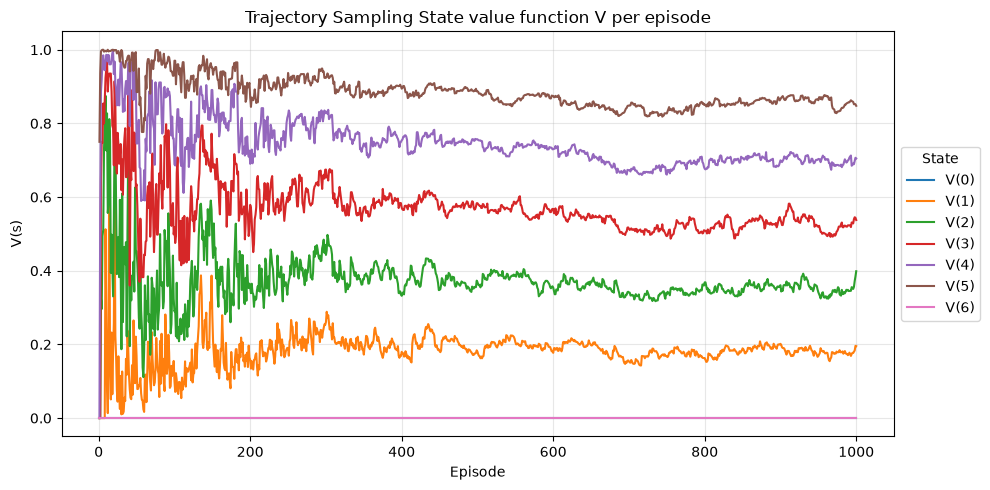

In [11]:

Q, V_track, pi, Q_track, pi_track = trajectory_sampling(slip_walk_seven, n_episodes=1000)
plot_v_track(V_track, title='Trajectory Sampling State value function V per episode')

## FrozenLake: which control algorithm works best?

Every algorithm above is trained on the slippery FrozenLake 4x4 (10,000 episodes) and on the standard 8x8 map (30,000 episodes).
All runs use γ = 0.99, at most 200 steps per episode, λ = 0.5 for the trace methods and the same seed.

Each run is compared with the optimal solution from policy iteration (DP):
- **P(success)**: how often the learned greedy policy reaches the goal over 1,000 evaluation episodes.
- **V(start)** and **mean |V − V\*|**: how close the learned values are to the optimal values V\*.

In [12]:
# Holes of Gymnasium's FrozenLake-v1 8x8 map
FROZEN_LAKE_8X8_HOLES = [19, 29, 35, 41, 42, 46, 49, 52, 54, 59]

frozen_lake = FrozenLake(n=4, seed=0)
frozen_lake_8x8 = FrozenLake(n=8, holes=FROZEN_LAKE_8X8_HOLES, seed=0)

frozen_lake.display(show_legend=True)
print()
frozen_lake_8x8.display(show_legend=False)

Legend: S=start  F=frozen  H=hole  G=goal  A=agent
| SA    |F     |F     |F     |
|   0   |  1   |  2   |  3   |
| F     |H     |F     |H     |
|   4   |  5   |  6   |  7   |
| F     |F     |F     |H     |
|   8   |  9   | 10   | 11   |
| H     |F     |F     |G     |
|  12   | 13   | 14   | 15   |

| SA    |F     |F     |F     |F     |F     |F     |F     |
|   0   |  1   |  2   |  3   |  4   |  5   |  6   |  7   |
| F     |F     |F     |F     |F     |F     |F     |F     |
|   8   |  9   | 10   | 11   | 12   | 13   | 14   | 15   |
| F     |F     |F     |H     |F     |F     |F     |F     |
|  16   | 17   | 18   | 19   | 20   | 21   | 22   | 23   |
| F     |F     |F     |F     |F     |H     |F     |F     |
|  24   | 25   | 26   | 27   | 28   | 29   | 30   | 31   |
| F     |F     |F     |H     |F     |F     |F     |F     |
|  32   | 33   | 34   | 35   | 36   | 37   | 38   | 39   |
| F     |H     |H     |F     |F     |F     |H     |F     |
|  40   | 41   | 42   | 43   | 44   | 45   | 46   |

In [13]:
GAMMA = 0.99
MAX_STEPS = 200
N_EVAL_EPISODES = 1000

TabularEnv = FrozenLake | BanditWalk

control_algorithms = {
    'Monte Carlo': mc_control,
    'Sarsa': sarsa,
    'Q-Learning': q_learning,
    'Double Q-Learning': double_q_learning,
    'Sarsa(λ=0.5)': partial(sarsa_lambda, lambda_=0.5),
    'Q(λ=0.5)': partial(q_lambda, lambda_=0.5),
    'Dyna-Q': dyna_q,
    'Trajectory Sampling': trajectory_sampling,
}


def run_all_algorithms(env: TabularEnv, n_episodes: int, seed: int = 0) -> dict:
    """Trains every control algorithm on env. Returns {name: (Q, V_track, pi)}."""
    results = {}
    for name, algorithm in control_algorithms.items():
        np.random.seed(seed)
        env.seed(seed)
        start = time.perf_counter()
        Q, V_track, pi, _, _ = algorithm(env, gamma=GAMMA, n_episodes=n_episodes, max_steps=MAX_STEPS)
        print(f'{name:<20} trained in {time.perf_counter() - start:6.1f}s')
        results[name] = (Q, V_track, pi)
    return results


def non_terminal_states(env: TabularEnv) -> list[int]:
    return [s for s in range(env.n_states) if s != env.goal and s not in env.holes]


def compare_algorithms(env: TabularEnv, results: dict, pi_opt, V_opt) -> None:
    """Prints each algorithm's success rate and value error, best value error first."""
    states = non_terminal_states(env)
    start = env.start_state

    rows = []
    for name, (_, V_track, pi) in results.items():
        p_success = probability_success(env, pi, n_episodes=N_EVAL_EPISODES, max_steps=MAX_STEPS, seed=123)
        v_error = np.abs(V_track[-1, states] - V_opt[states]).mean()
        rows.append((name, p_success, V_track[-1, start], v_error))
    rows.sort(key=lambda row: row[3])

    p_opt = probability_success(env, pi_opt, n_episodes=N_EVAL_EPISODES, max_steps=MAX_STEPS, seed=123)
    print(f"{'Algorithm':<20} {'P(success)':>10} {'V(start)':>9} {'mean |V - V*|':>14}")
    print(f"{'Optimal (DP)':<20} {p_opt:>10.3f} {V_opt[start]:>9.3f} {0:>14.3f}")
    for name, p_success, v_start, v_error in rows:
        print(f'{name:<20} {p_success:>10.3f} {v_start:>9.3f} {v_error:>14.3f}')

In [14]:
def plot_learning_curves(env: TabularEnv, results: dict, V_opt, title: str, log_scale: bool = False) -> None:
    """Left: V(start) per episode against V*(start). Right: mean |V - V*| over non-terminal states.

    log_scale=True puts the episode axis on a log scale, which stretches out the early episodes.
    """
    states = non_terminal_states(env)
    start = env.start_state

    fig, (ax_start, ax_error) = plt.subplots(1, 2, figsize=(15, 5))
    for name, (_, V_track, _) in results.items():
        episodes = np.arange(1, len(V_track) + 1)
        ax_start.plot(episodes, V_track[:, start], label=name, linewidth=1)
        ax_error.plot(episodes, np.abs(V_track[:, states] - V_opt[states]).mean(axis=1), label=name, linewidth=1)

    ax_start.axhline(V_opt[start], color='black', linestyle='--', label='Optimal V*(start)')
    ax_start.set_ylabel('V(start)')
    ax_start.set_title(f'{title}: value of the start state')
    ax_error.set_ylabel('mean |V - V*|')
    ax_error.set_title(f'{title}: distance from the optimal values')
    for ax in (ax_start, ax_error):
        if log_scale:
            ax.set_xscale('log')
        ax.set_xlabel('Episode (log scale)' if log_scale else 'Episode')
        ax.grid(True, alpha=0.3)
    handles, labels = ax_start.get_legend_handles_labels()  # includes the optimal V* line
    ax_error.legend(handles, labels, loc='center left', bbox_to_anchor=(1.0, 0.5), title='Algorithm')
    fig.tight_layout()
    plt.show()


def plot_state_values(env: TabularEnv, results: dict, V_opt, title: str, rows: int = 3, cols: int = 3,
                      log_scale: bool = False) -> None:
    """One subplot per non-terminal state comparing V(s) per episode across algorithms, rows x cols per figure.

    log_scale=True puts the episode axis on a log scale, which stretches out the early episodes.
    """
    states = non_terminal_states(env)
    per_figure = rows * cols
    n_figures = -(-len(states) // per_figure)  # ceiling division

    for figure in range(n_figures):
        figure_states = states[figure * per_figure:(figure + 1) * per_figure]
        figure_rows = -(-len(figure_states) // cols)  # the last figure may need fewer rows
        fig, axes = plt.subplots(figure_rows, cols, figsize=(16, 3.3 * figure_rows + 1.5),
                                 squeeze=False, layout='constrained')

        for ax, s in zip(axes.flat, figure_states):
            for name, (_, V_track, _) in results.items():
                ax.plot(np.arange(1, len(V_track) + 1), V_track[:, s], label=name, linewidth=0.8)
            ax.axhline(V_opt[s], color='black', linestyle='--', linewidth=1, label='Optimal V*(s)')
            board_cols = env.display_cols
            position = f'  (row {s // board_cols}, col {s % board_cols})' if env.n_states > board_cols else ''  # 2D boards only
            ax.set_title(f'V({s}){position}   V* = {V_opt[s]:.3f}')
            if log_scale:
                ax.set_xscale('log')
            ax.grid(True, alpha=0.3)
        for ax in axes.flat[len(figure_states):]:
            ax.axis('off')

        handles, labels = axes.flat[0].get_legend_handles_labels()
        legend = fig.legend(handles, labels, loc='outside right center', title='Algorithm')
        for line in legend.get_lines():
            line.set_linewidth(2.5)
        fig.suptitle(f'{title}: V(s) per episode for each non-terminal state ({figure + 1}/{n_figures})')
        fig.supxlabel('Episode (log scale)' if log_scale else 'Episode')
        fig.supylabel('V(s)')
        plt.show()

### FrozenLake 4x4 (10,000 episodes)

In [15]:
pi_opt_4x4, V_opt_4x4 = policy_iteration(frozen_lake, gamma=GAMMA)
results_4x4 = run_all_algorithms(frozen_lake, n_episodes=10_000)

Monte Carlo          trained in    0.7s
Sarsa                trained in    0.7s
Q-Learning           trained in    1.0s
Double Q-Learning    trained in    1.4s
Sarsa(λ=0.5)         trained in    1.2s
Q(λ=0.5)             trained in    1.3s
Dyna-Q               trained in    9.1s
Trajectory Sampling  trained in   36.2s


Algorithm            P(success)  V(start)  mean |V - V*|
Optimal (DP)              0.805     0.542          0.000
Trajectory Sampling       0.815     0.533          0.006
Dyna-Q                    0.805     0.533          0.007
Q-Learning                0.815     0.529          0.010
Q(λ=0.5)                  0.805     0.530          0.013
Double Q-Learning         0.775     0.517          0.061
Sarsa(λ=0.5)              0.775     0.297          0.209
Sarsa                     0.775     0.285          0.227
Monte Carlo               0.769     0.257          0.253


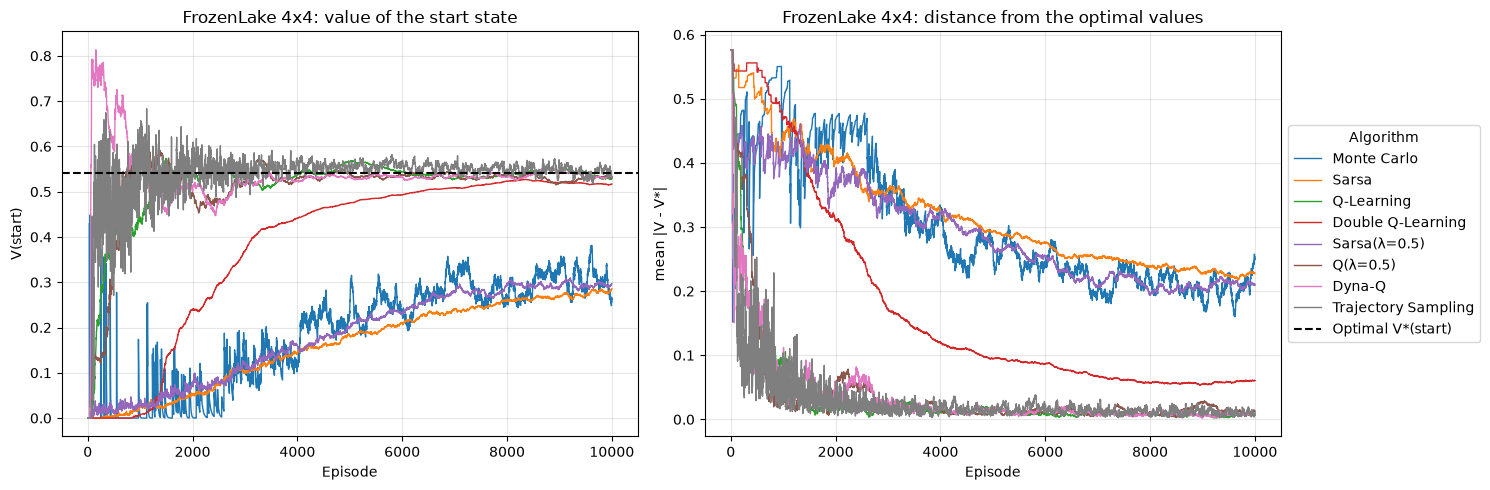

In [16]:
compare_algorithms(frozen_lake, results_4x4, pi_opt_4x4, V_opt_4x4)
plot_learning_curves(frozen_lake, results_4x4, V_opt_4x4, title='FrozenLake 4x4')

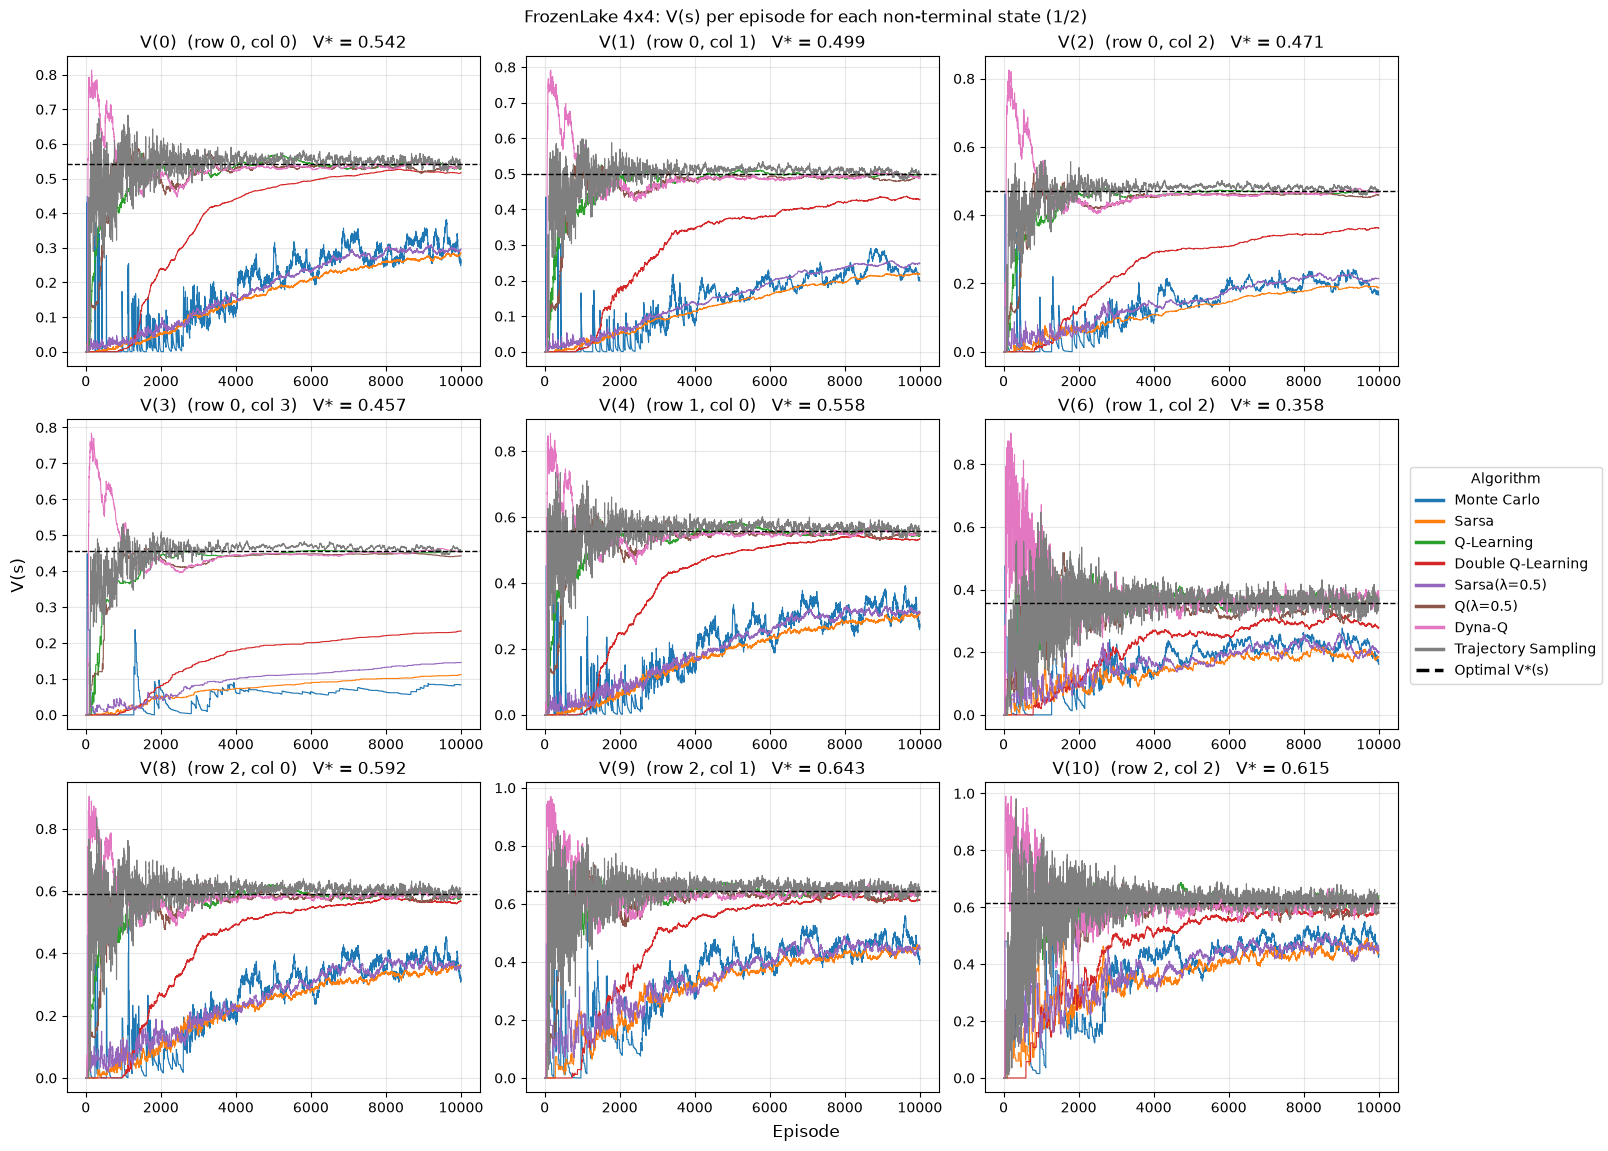

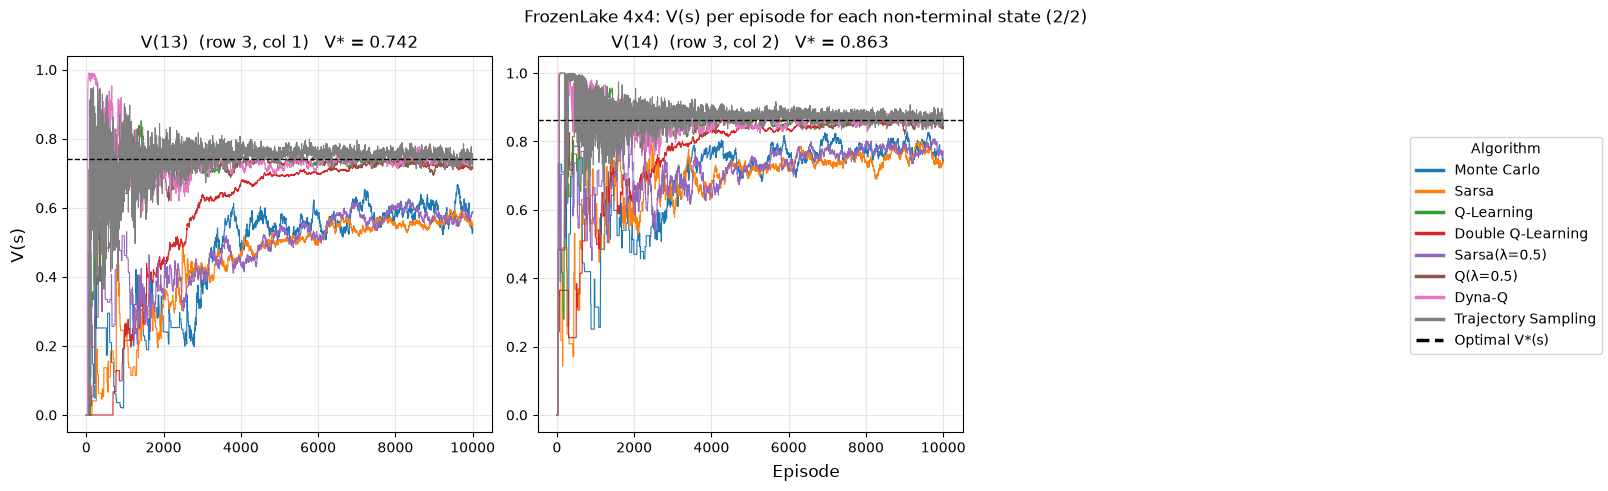

In [17]:
plot_state_values(frozen_lake, results_4x4, V_opt_4x4, title='FrozenLake 4x4')

### FrozenLake 8x8 (30,000 episodes)

Training takes about 10 minutes: roughly 7–8 minutes for Trajectory Sampling, 1–2 minutes for Dyna-Q and under 15 seconds for each of the others.

In [18]:
pi_opt_8x8, V_opt_8x8 = policy_iteration(frozen_lake_8x8, gamma=GAMMA)
results_8x8 = run_all_algorithms(frozen_lake_8x8, n_episodes=30_000)

Monte Carlo          trained in    6.1s
Sarsa                trained in    7.0s
Q-Learning           trained in    8.0s
Double Q-Learning    trained in   10.6s
Sarsa(λ=0.5)         trained in   11.5s
Q(λ=0.5)             trained in   10.6s
Dyna-Q               trained in   77.8s
Trajectory Sampling  trained in  451.7s


Algorithm            P(success)  V(start)  mean |V - V*|
Optimal (DP)              0.847     0.415          0.000
Dyna-Q                    0.854     0.422          0.011
Trajectory Sampling       0.843     0.419          0.019
Q(λ=0.5)                  0.862     0.418          0.027
Q-Learning                0.861     0.410          0.028
Double Q-Learning         0.716     0.317          0.127
Sarsa(λ=0.5)              0.877     0.253          0.177
Sarsa                     0.746     0.240          0.185
Monte Carlo               0.004     0.012          0.293


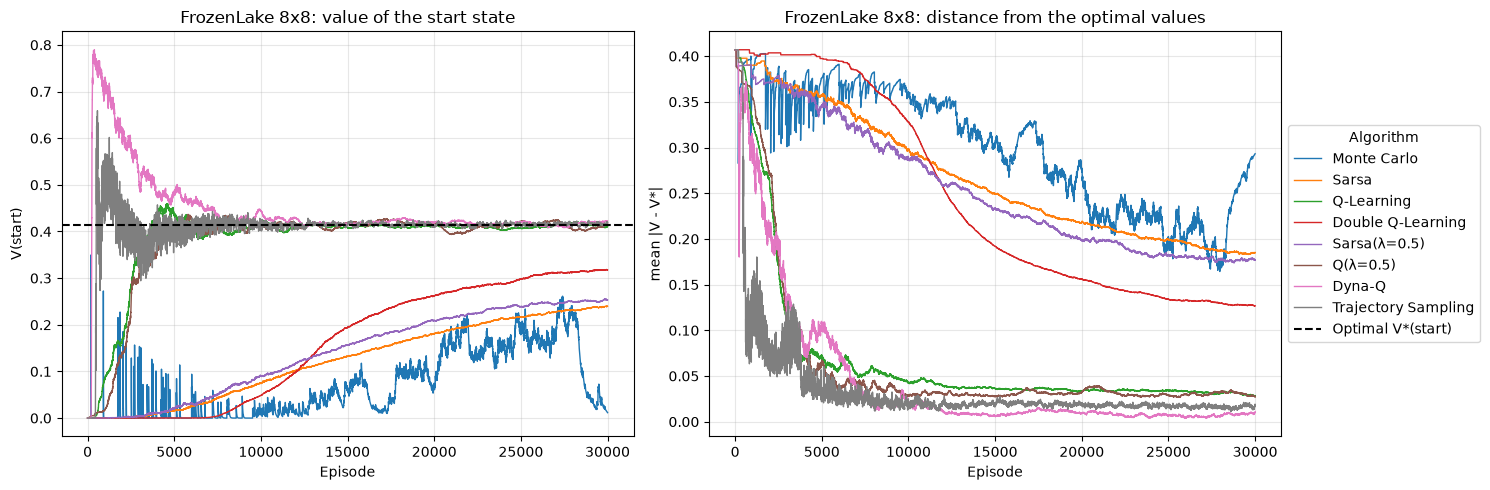

In [19]:
compare_algorithms(frozen_lake_8x8, results_8x8, pi_opt_8x8, V_opt_8x8)
plot_learning_curves(frozen_lake_8x8, results_8x8, V_opt_8x8, title='FrozenLake 8x8')

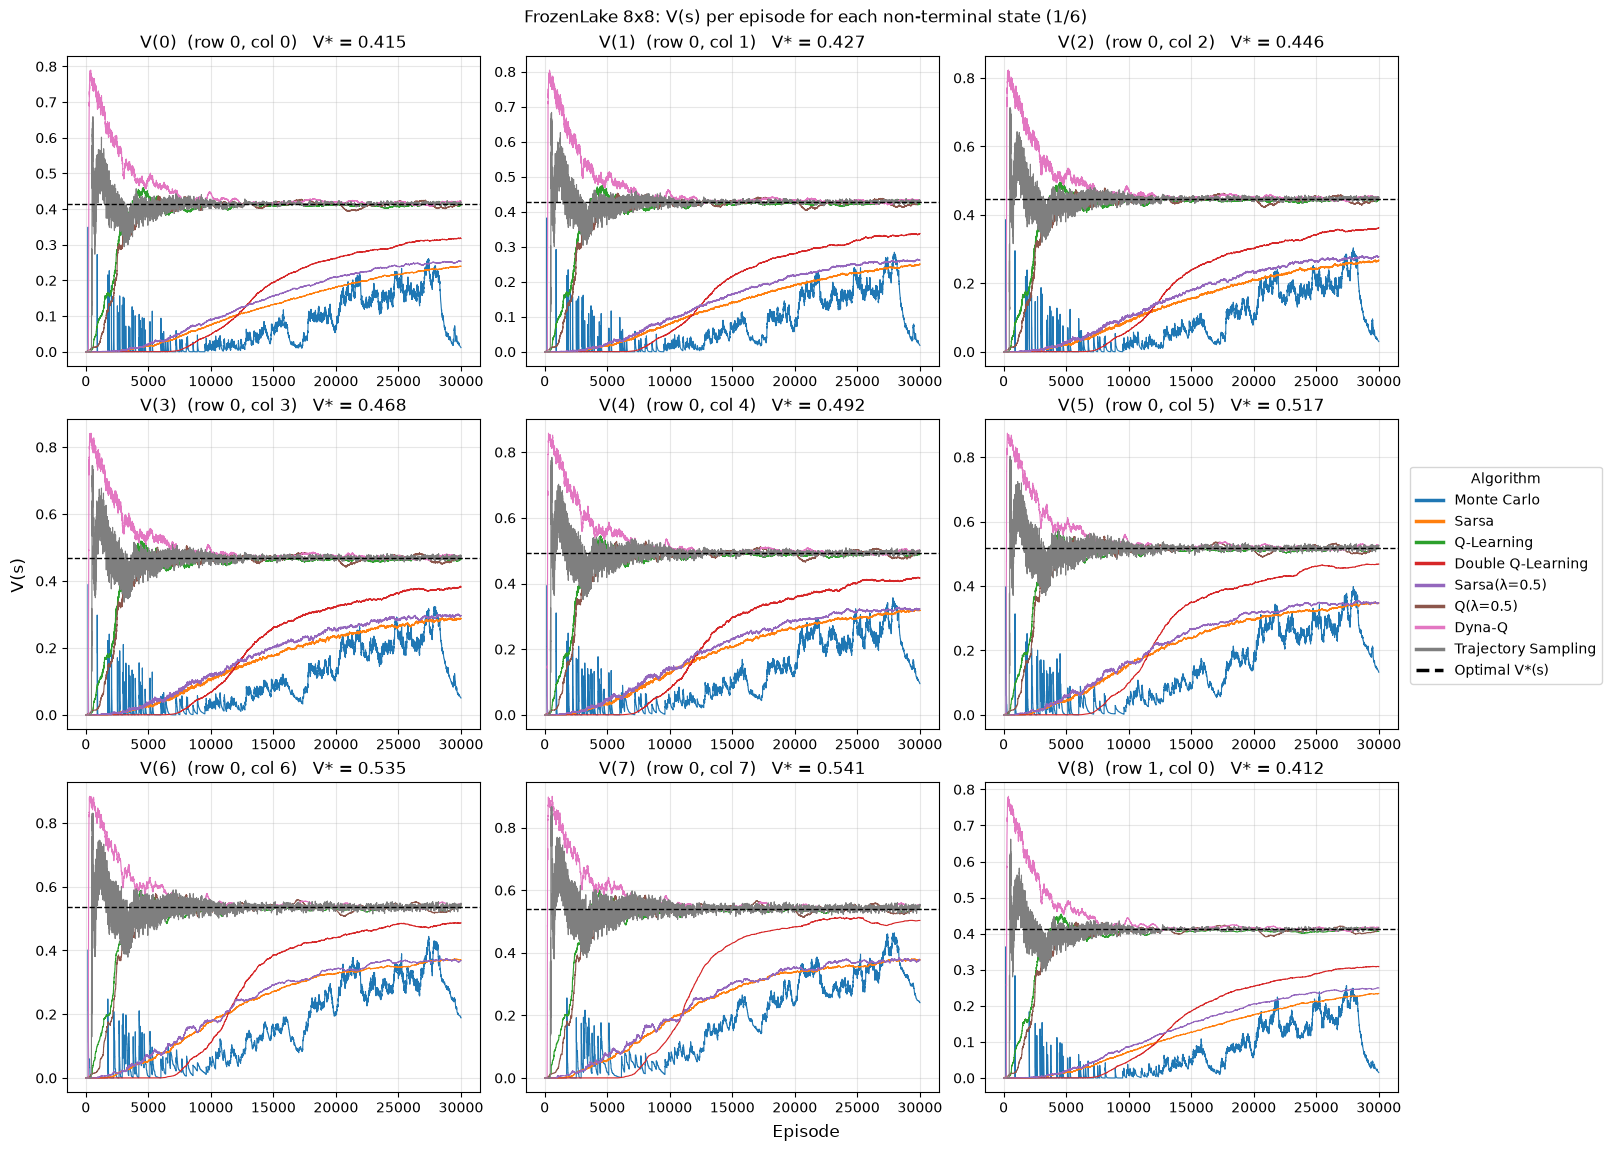

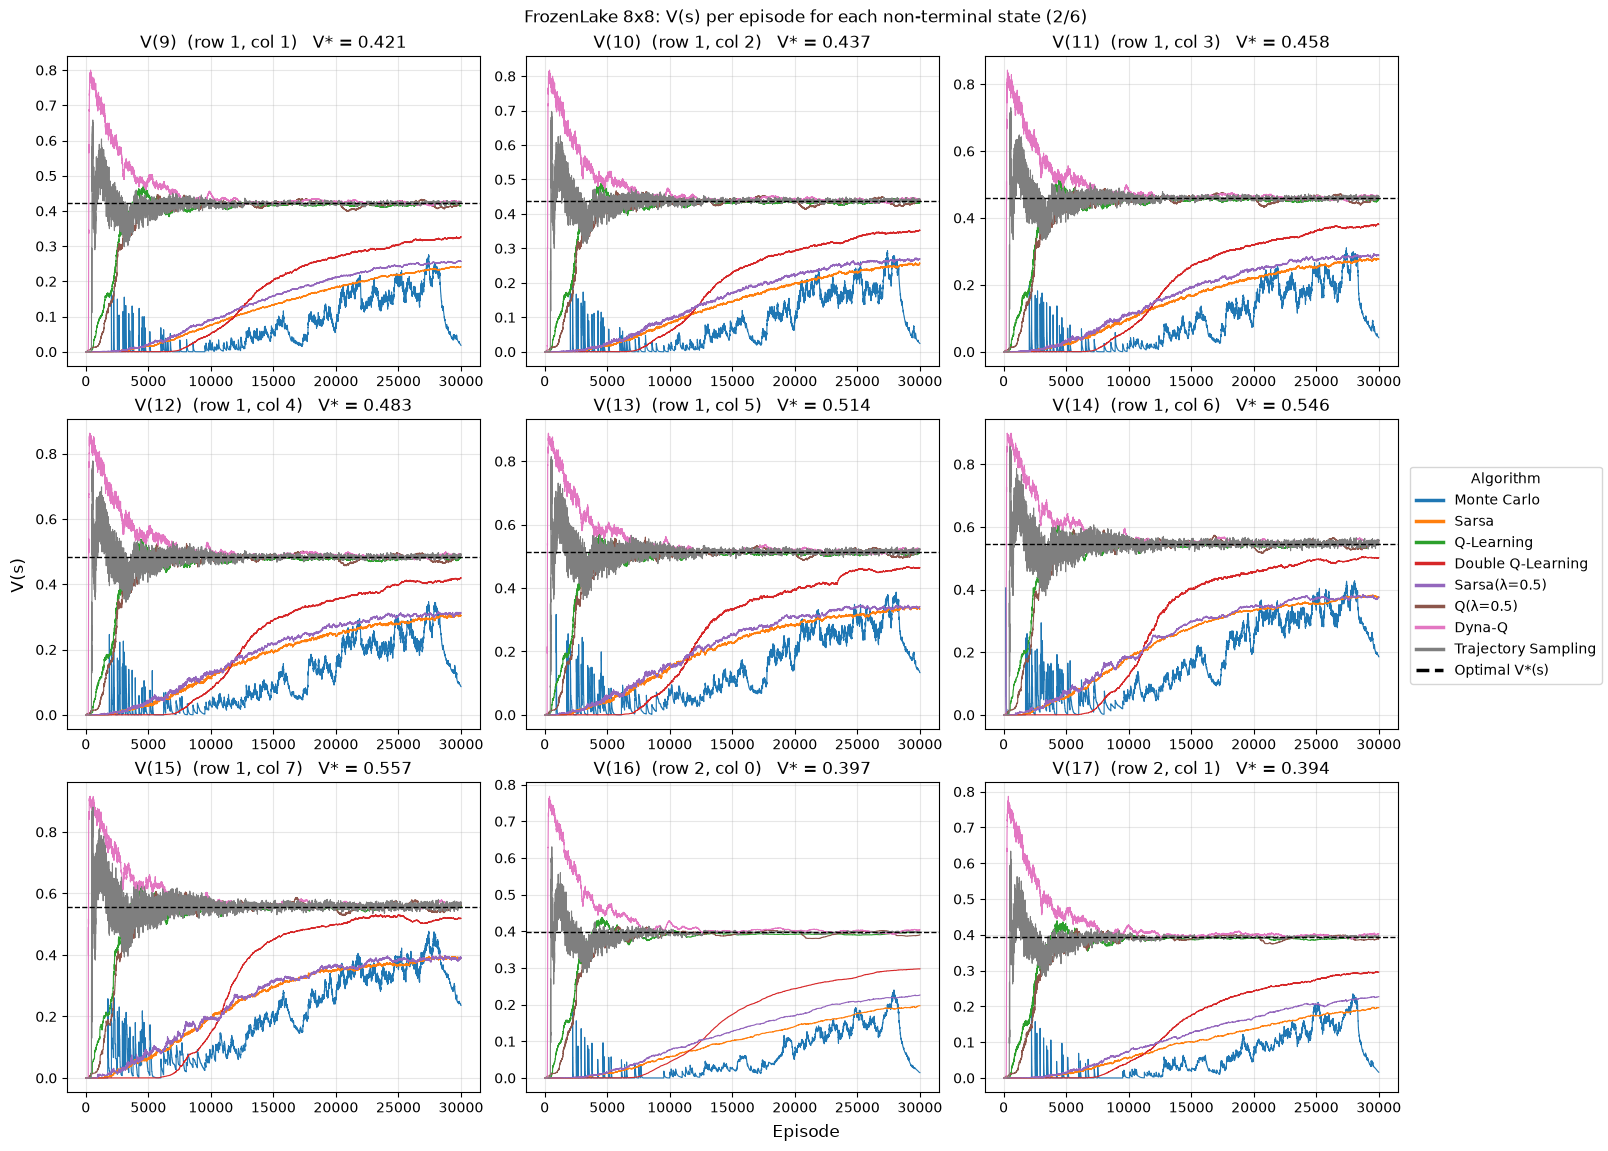

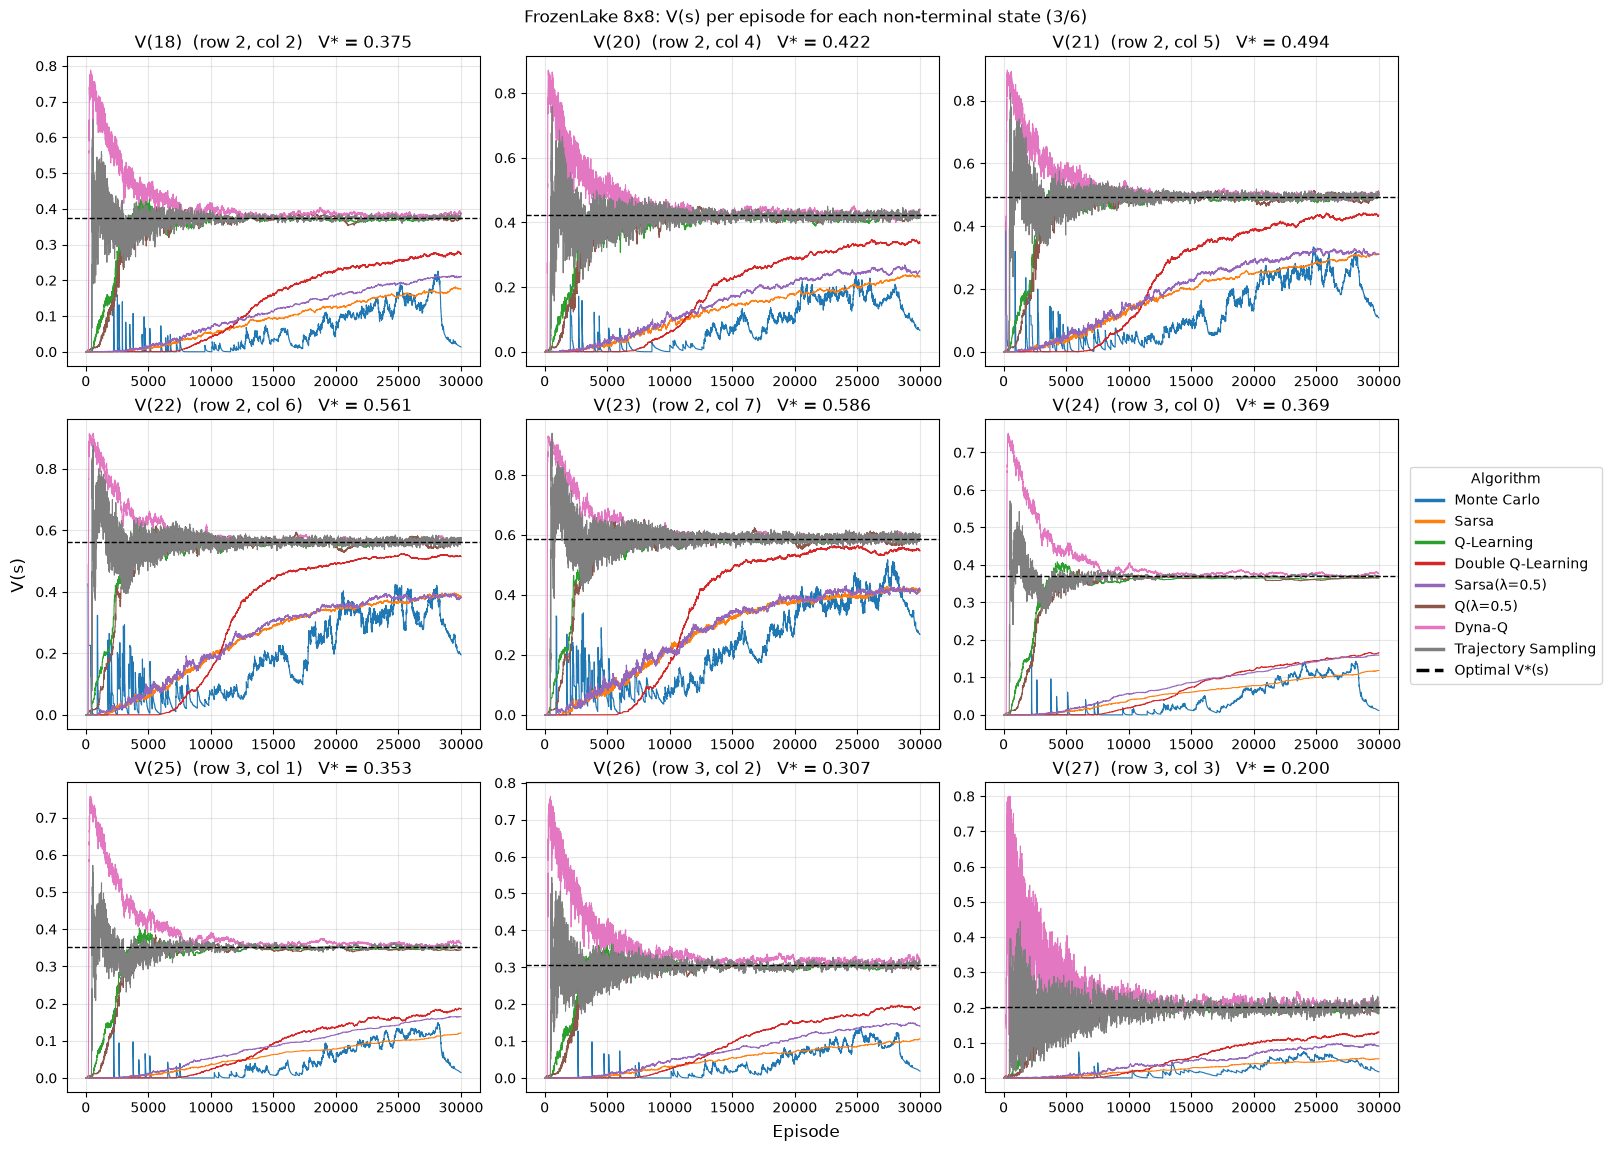

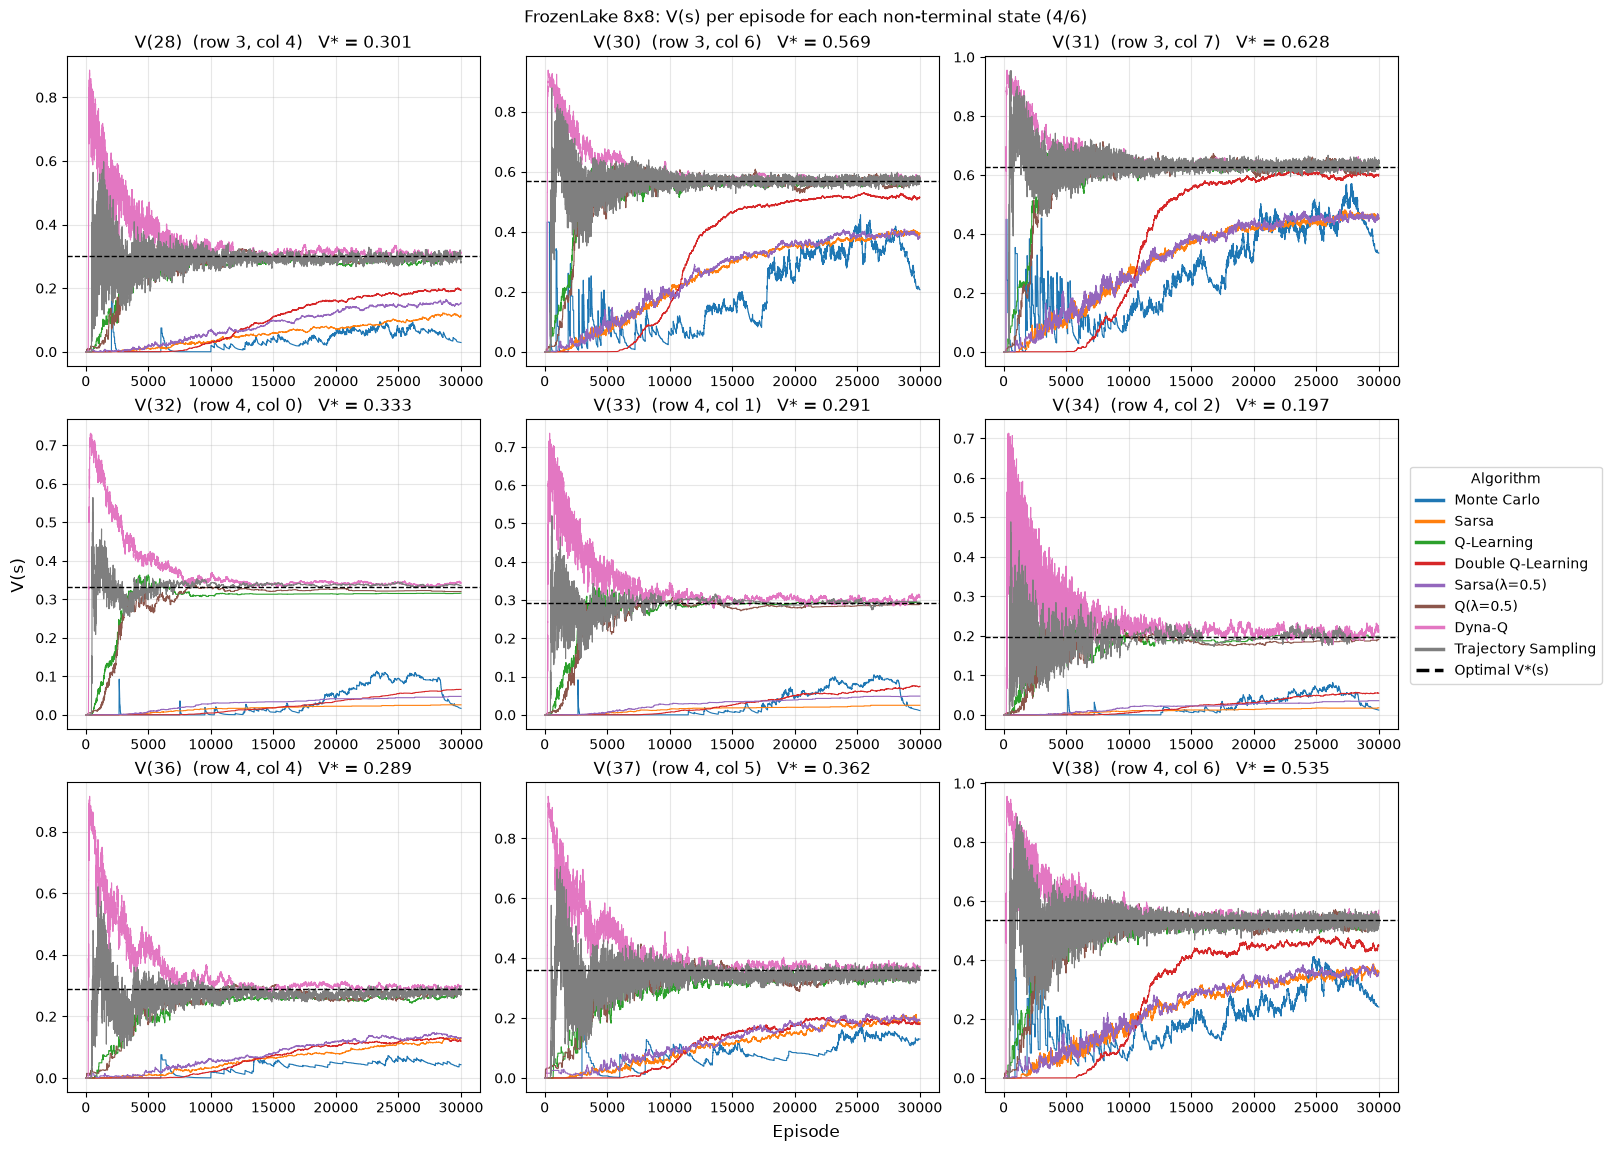

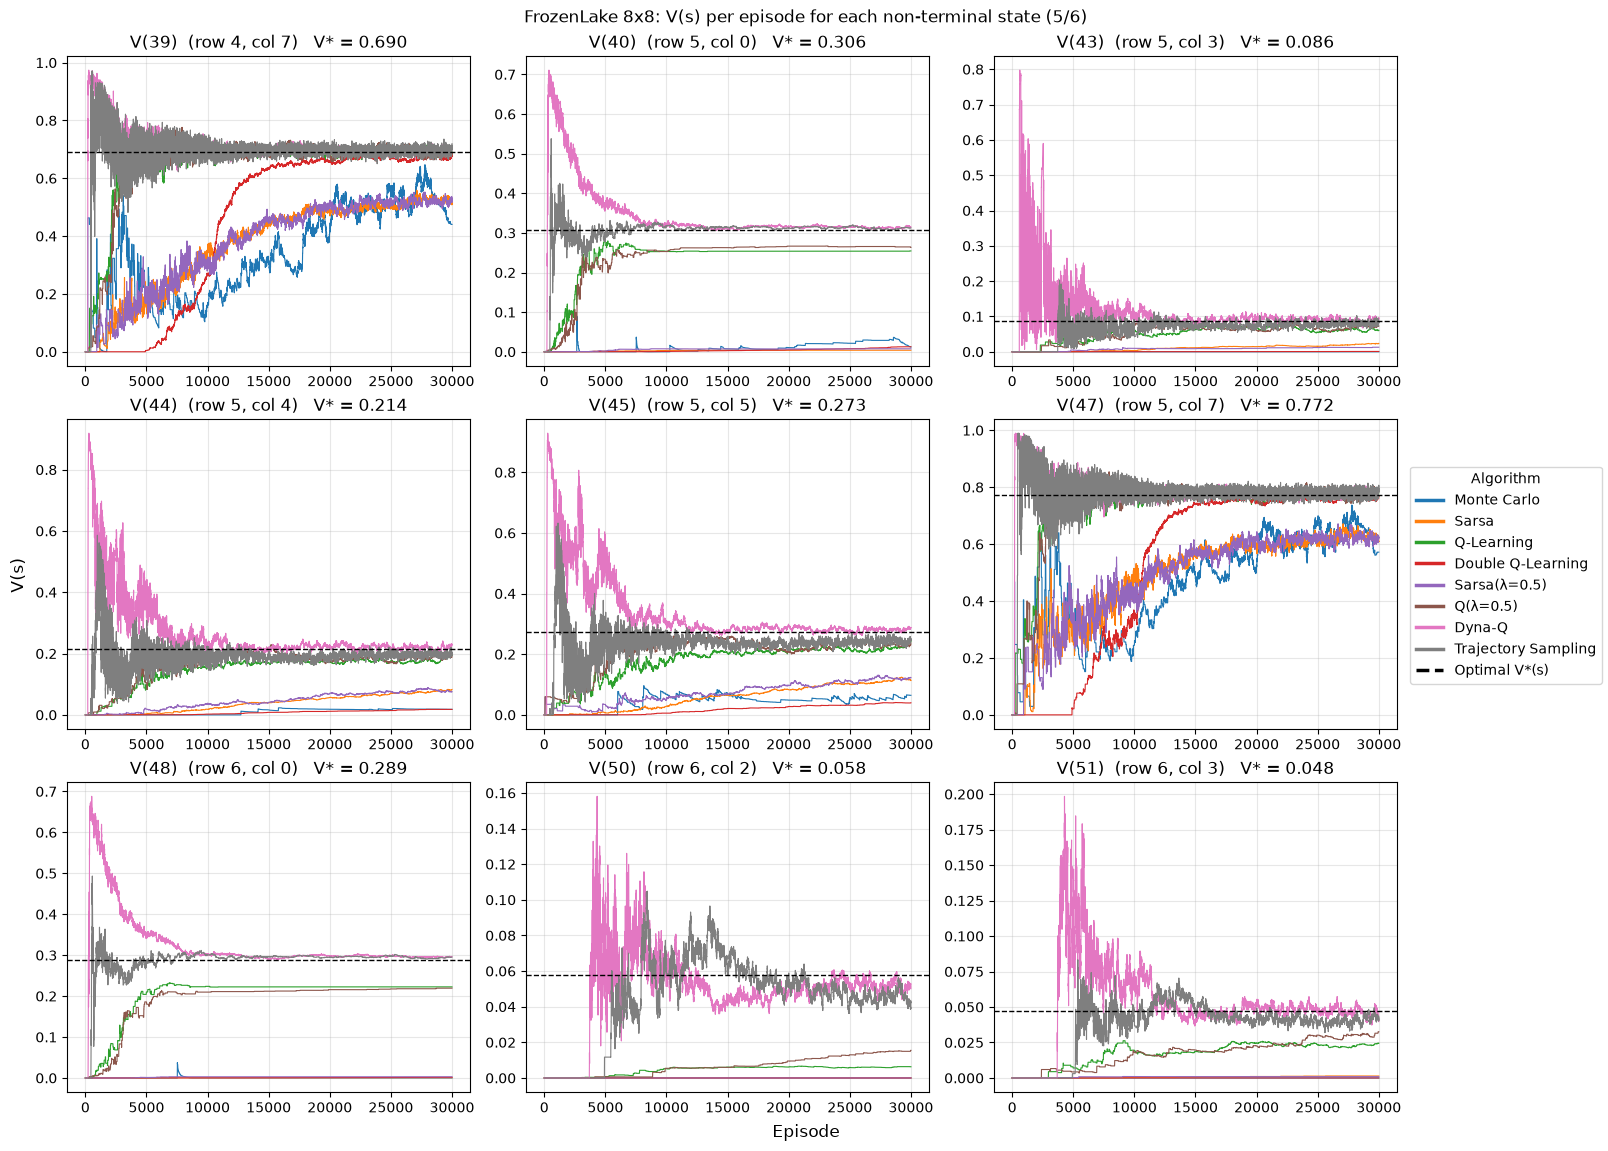

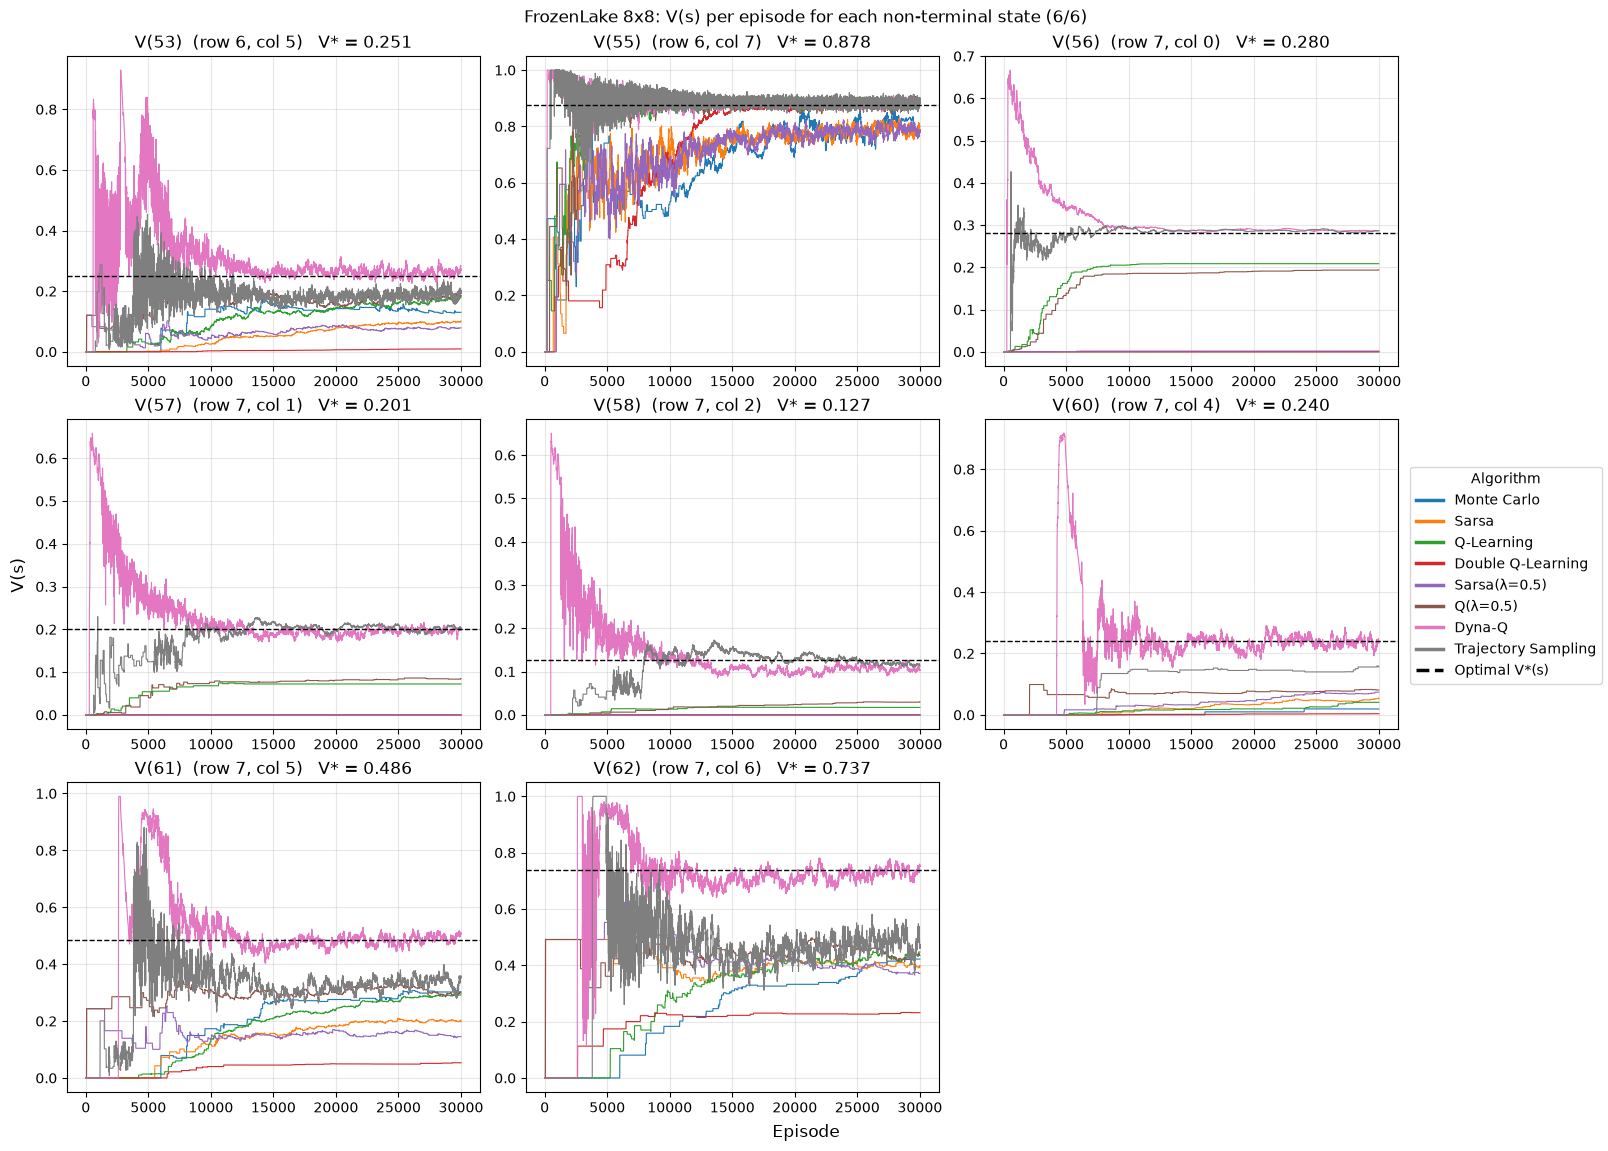

In [20]:
plot_state_values(frozen_lake_8x8, results_8x8, V_opt_8x8, title='FrozenLake 8x8')

### Takeaways

- **Q-learning, Q(λ), Dyna-Q and Trajectory Sampling** learn close to the optimal values on both maps. Dyna-Q gets closest per episode because it replays its learned model; Q-learning and Q(λ) get almost as close for a small fraction of the compute.
- **Sarsa and Sarsa(λ)** find good greedy policies, but their V(start) stays well below V\*. They are on-policy, so they learn the value of the ε-greedy policy (still exploring 10% of the time), not of the optimal policy.
- **Double Q-learning** converges more slowly, because each table only gets half the updates.
- **Monte Carlo** works on 4x4 but is unstable on 8x8. Its greedy policy reaches about 75% success at times and then collapses. Without bootstrapping, when play further along the path gets worse, the start state's action values all fall together until the agent is effectively acting at random. Its final score varies a lot between seeds.
- A **P(success) slightly above the optimal policy's** is evaluation noise (about ±0.01 over 1,000 episodes), plus the fact that the DP policy maximises *discounted* return, not success rate.

## BanditWalk (8 states): the same comparison

The deterministic walk with states 0–7: hole at 0, goal at 7, start at 4. Every move goes exactly where it is aimed.
Each algorithm gets 3,000 episodes with the same settings as FrozenLake (γ = 0.99, at most 200 steps per episode, λ = 0.5).

In [21]:
bandit_walk_eight = BanditWalk(n_states=8, seed=0)
bandit_walk_eight.display(show_legend=True)

Legend: G=goal  H=hole  .=frozen  A=agent
| H     |.     |.     |.     |.A    |.     |.     |G     |
|   0   |  1   |  2   |  3   |  4   |  5   |  6   |  7   |


In [22]:
pi_opt_walk, V_opt_walk = policy_iteration(bandit_walk_eight, gamma=GAMMA)
results_walk = run_all_algorithms(bandit_walk_eight, n_episodes=3_000)

Monte Carlo          trained in    0.1s
Sarsa                trained in    0.1s
Q-Learning           trained in    0.1s
Double Q-Learning    trained in    0.1s
Sarsa(λ=0.5)         trained in    0.1s
Q(λ=0.5)             trained in    0.1s
Dyna-Q               trained in    0.6s
Trajectory Sampling  trained in    0.2s


Algorithm            P(success)  V(start)  mean |V - V*|
Optimal (DP)              1.000     0.980          0.000
Dyna-Q                    1.000     0.980          0.000
Trajectory Sampling       1.000     0.980          0.000
Q(λ=0.5)                  1.000     0.980          0.000
Q-Learning                1.000     0.980          0.000
Double Q-Learning         1.000     0.980          0.000
Monte Carlo               1.000     0.978          0.042
Sarsa(λ=0.5)              1.000     0.978          0.047
Sarsa                     1.000     0.977          0.052


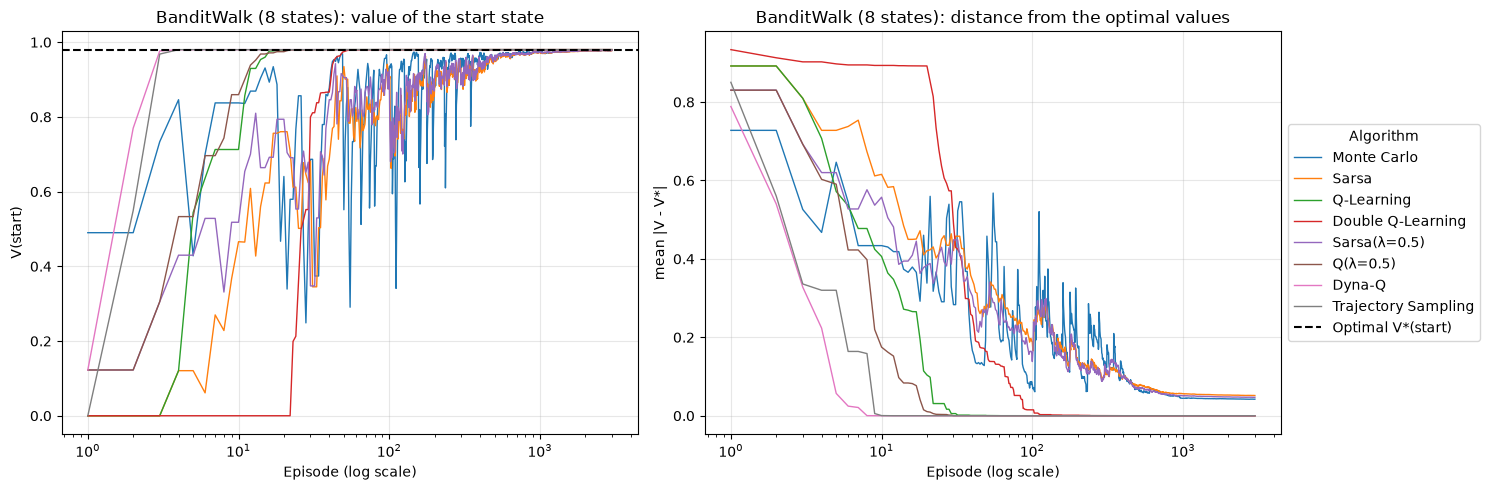

In [26]:
compare_algorithms(bandit_walk_eight, results_walk, pi_opt_walk, V_opt_walk)
plot_learning_curves(bandit_walk_eight, results_walk, V_opt_walk, title='BanditWalk (8 states)', log_scale=True)

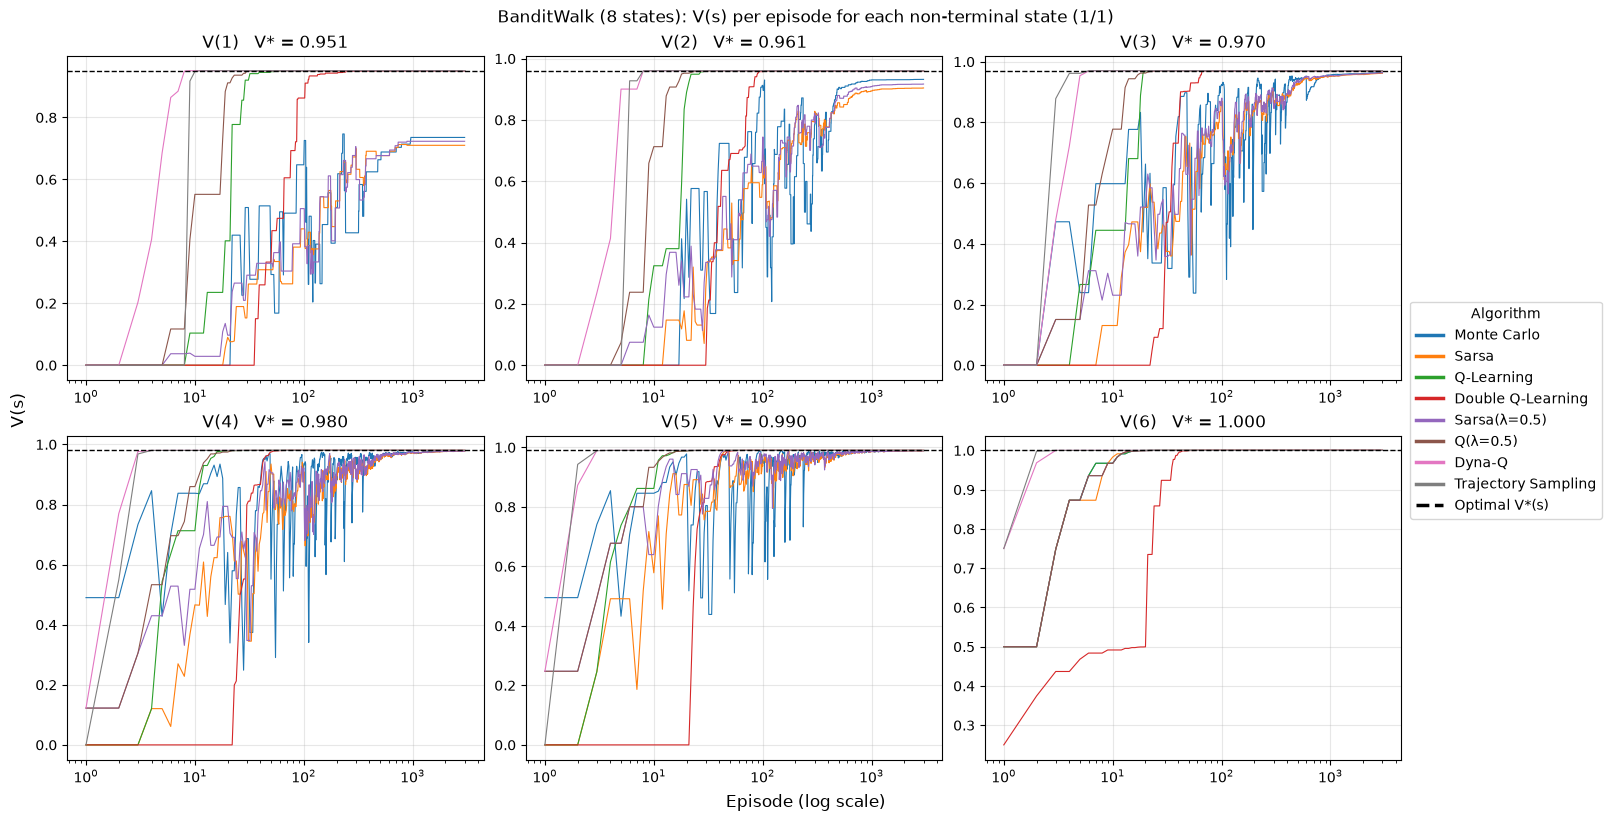

In [25]:
plot_state_values(bandit_walk_eight, results_walk, V_opt_walk, title='BanditWalk (8 states)', log_scale=True)

### Takeaways for the walk

- Every algorithm finds the optimal policy (always move right) and reaches the goal every time. Without slipping, the problem is easy.
- **Q-learning, Double Q-learning, Q(λ), Dyna-Q and Trajectory Sampling** converge exactly to V\*. The planning methods get there in under 10 episodes, Q-learning and Q(λ) in about 20, and Double Q-learning in about 80.
- **Monte Carlo, Sarsa and Sarsa(λ)** end below V\* near the hole (V(1) ≈ 0.71–0.74 against V\* = 0.951). They learn the value of the ε-greedy policy, and from state 1 its random 5% of left moves fall straight into the hole.